## 1. Dense Neural Network

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 496kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.08MB/s]


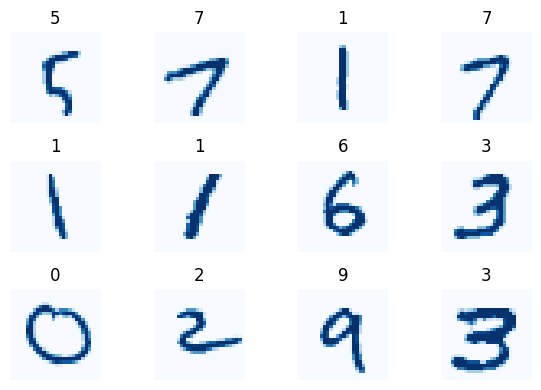

In [ ]:
# 1) Define transforms
transform = transforms.ToTensor()  # converts to float32 tensor in [0, 1], shape [C, H, W]

# 2) Load MNIST as Dataset objects
train_ds = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# 3) Create a DataLoader - class which control the data flow
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False)

# 4) Visualize 12 images
fig, ax = plt.subplots(3, 4, figsize=(6, 4))

for i in range(12):
    img, label = train_ds[100 + i]      # img: tensor [1, 28, 28], label: int
    img2d = img.squeeze(0)              # -> [28, 28] for imshow

    ax[i//4, i%4].imshow(img2d, cmap="Blues")
    ax[i//4, i%4].axis("off")
    ax[i//4, i%4].set_title(str(label))

plt.tight_layout()
plt.show()


In [ ]:
img, label = train_ds[110]
img

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [ ]:
first_test_img, first_test_label = test_ds[0]
print(first_test_label)

In [ ]:
import numpy as np
np.random.seed(123)  # for reproducibility

import torch
import torch.nn as nn
from torch.utils.data import  TensorDataset, random_split

torch.manual_seed(123)  # reproducibility for torch


In [ ]:
# (Flashback from optimization algs notebook)

# NOTE: after our PyTorch data-loading cells, we have train_ds and test_ds (torchvision MNIST datasets).

# flatten 28*28 images to a 784 vector for each image
num_pixels = 28 * 28

X_train = train_ds.data.float().view(-1, num_pixels) / 255.0   # (60000, 784), float32 in [0,1]
y_train = train_ds.targets.long()                               # (60000,), int labels 0..9

X_test  = test_ds.data.float().view(-1, num_pixels) / 255.0     # (10000, 784)
y_test  = test_ds.targets.long()                                # (10000,)

num_classes = 10

# define baseline model (PyTorch)
class BaselineDense(nn.Module):
    def __init__(self, in_features, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(in_features, in_features)  # one fully-connected layer
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(in_features, num_classes)  # outputs logits (no softmax here)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model_dense = BaselineDense(num_pixels, num_classes)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# loss + optimizer (CrossEntropyLoss expects class indices, not one-hot encoded)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_dense.parameters())

# Create train/val split
full_train = TensorDataset(X_train, y_train)
val_size = int(0.1 * len(full_train))
train_size = len(full_train) - val_size
train_subset, val_subset = random_split(full_train, [train_size, val_size])

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_subset, batch_size=32, shuffle=False)

# Training loop
history_dense = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}


model_dense = model_dense.to(device)

for epoch in range(10):
    # ---- train ----
    model_dense.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model_dense(xb)

        loss = criterion(logits, yb)

        loss.backward()

        optimizer.step()

        train_loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == yb).sum().item()
        train_total += xb.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---- validation ----
    model_dense.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for xb, yb in val_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model_dense(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == yb).sum().item()
            val_total += xb.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history_dense["loss"].append(train_loss)
    history_dense["accuracy"].append(train_acc)
    history_dense["val_loss"].append(val_loss)
    history_dense["val_accuracy"].append(val_acc)

    print(f"Epoch {epoch+1:02d}/10 - loss: {train_loss:.4f} - acc: {train_acc:.4f} - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")

Epoch 01/10 - loss: 0.2180 - acc: 0.9360 - val_loss: 0.1152 - val_acc: 0.9657
Epoch 02/10 - loss: 0.0846 - acc: 0.9744 - val_loss: 0.0832 - val_acc: 0.9737
Epoch 03/10 - loss: 0.0546 - acc: 0.9824 - val_loss: 0.0858 - val_acc: 0.9748
Epoch 04/10 - loss: 0.0381 - acc: 0.9878 - val_loss: 0.0704 - val_acc: 0.9808
Epoch 05/10 - loss: 0.0288 - acc: 0.9907 - val_loss: 0.0761 - val_acc: 0.9790
Epoch 06/10 - loss: 0.0215 - acc: 0.9926 - val_loss: 0.0804 - val_acc: 0.9790
Epoch 07/10 - loss: 0.0166 - acc: 0.9947 - val_loss: 0.0881 - val_acc: 0.9767
Epoch 08/10 - loss: 0.0163 - acc: 0.9941 - val_loss: 0.0925 - val_acc: 0.9790
Epoch 09/10 - loss: 0.0140 - acc: 0.9955 - val_loss: 0.0788 - val_acc: 0.9817
Epoch 10/10 - loss: 0.0104 - acc: 0.9963 - val_loss: 0.0976 - val_acc: 0.9797


In [ ]:
print(history_dense.keys())

In [ ]:
# model summary
!pip install torchinfo
from torchinfo import summary

# Print a layer table including output shapes and param counts
summary(
    model_dense,
    input_size=(1, num_pixels),   # (batch, features) -> (1, 784)
    col_names=("input_size", "output_size", "num_params"),
    row_settings=("depth", "var_names"),
    verbose=0
)


Layer (type (var_name):depth-idx)        Input Shape               Output Shape              Param #
BaselineDense (BaselineDense)            [1, 784]                  [1, 10]                   --
├─Linear (fc1): 1-1                      [1, 784]                  [1, 784]                  615,440
├─ReLU (relu): 1-2                       [1, 784]                  [1, 784]                  --
├─Linear (fc2): 1-3                      [1, 784]                  [1, 10]                   7,850
Total params: 623,290
Trainable params: 623,290
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.62
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 2.49
Estimated Total Size (MB): 2.50

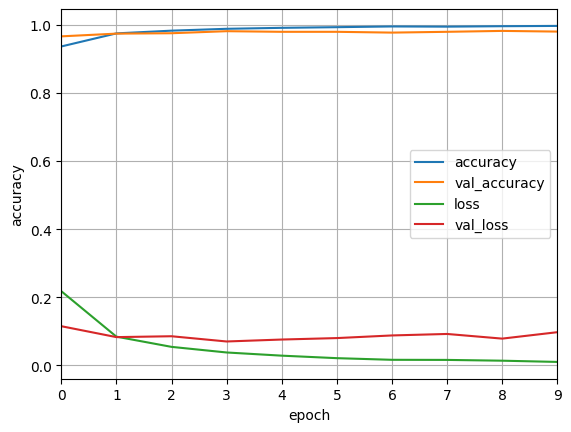

In [ ]:
# summarize history for loss
plt.plot(history_dense['accuracy'])
plt.plot(history_dense['val_accuracy'])
plt.plot(history_dense['loss'])
plt.plot(history_dense['val_loss'])
plt.xlim(0,9)
plt.grid()
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['accuracy', 'val_accuracy','loss', 'val_loss'], loc='best')
plt.show()

In [ ]:
# Evaluate model on test data
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_dense = model_dense.to(device)

test_ds_dense = TensorDataset(X_test, y_test)
test_loader_dense = DataLoader(test_ds_dense, batch_size=32, shuffle=False)

model_dense.eval()
test_loss_sum = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for i, (xb, yb) in enumerate(test_loader_dense):

        xb = xb.to(device)
        yb = yb.to(device)

        logits = model_dense(xb)
        loss = criterion(logits, yb)

        test_loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        test_correct += (preds == yb).sum().item()
        test_total += xb.size(0)

test_loss = test_loss_sum / test_total
test_acc = test_correct / test_total
print("Test Loss:", round(test_loss, 5), "\nTest Accuracy:", round(test_acc, 3))


Test Loss: 0.08956 
Test Accuracy: 0.98


## 2. Convolutional Neural Network

In [ ]:
# Preprocess input data for CNN model

# In PyTorch, MNIST is already loaded as train_ds / test_ds (torchvision datasets).
# We re-create X_train/X_test tensors in a way that mirrors the Keras preprocessing steps.

# Keras uses channels-last: (N, 28, 28, 1)
# PyTorch CNNs use channels-first: (N, 1, 28, 28)
X_train = train_ds.data.unsqueeze(1).float() / 255.0   # (60000, 1, 28, 28)
y_train = train_ds.targets.long()                      # (60000,)

X_test  = test_ds.data.unsqueeze(1).float() / 255.0    # (10000, 1, 28, 28)
y_test  = test_ds.targets.long()                       # (10000,)


In [ ]:
# Preprocess class labels
# In PyTorch, we DO NOT one-hot encode for standard classification.
# nn.CrossEntropyLoss expects integer class indices (0..9).
Y_train = y_train
num_classes = 10


In [ ]:
# Define model architecture

import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # PyTorch expects N C H W, so in_channels=1
        self.conv = nn.Conv2d(in_channels=1, out_channels=28, kernel_size=3, padding='same')

        #  MaxPooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Flattening to 1 dimension
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(28 * 14 * 14, 32)

        self.relu = nn.ReLU()

        # regularization
        self.dropout = nn.Dropout(0.2)

        # Final layer
        self.fc2 = nn.Linear(32, 10)

    def forward(self, x):
        x = self.conv(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = CNN()

In [ ]:
# Compile model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

In [ ]:
# Fit model on training data

#from torch.utils.data import TensorDataset, DataLoader, random_split

# Create dataset
full_train = TensorDataset(X_train, Y_train)

# Validation split
val_size = int(0.1 * len(full_train))
train_size = len(full_train) - val_size
train_subset, val_subset = random_split(full_train, [train_size, val_size])

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_subset, batch_size=32, shuffle=False)

history_cnn = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(10):
    # ---- Training phase ----
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == yb).sum().item()
        train_total += xb.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---- Validation phase ----
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == yb).sum().item()
            val_total += xb.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history_cnn["loss"].append(train_loss)
    history_cnn["accuracy"].append(train_acc)
    history_cnn["val_loss"].append(val_loss)
    history_cnn["val_accuracy"].append(val_acc)

    print(f"Epoch {epoch+1:02d}/10 - "
          f"loss: {train_loss:.4f} - acc: {train_acc:.4f} - "
          f"val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f}")


Epoch 01/10 - loss: 0.4717 - acc: 0.8491 - val_loss: 0.1912 - val_acc: 0.9437
Epoch 02/10 - loss: 0.2440 - acc: 0.9244 - val_loss: 0.1309 - val_acc: 0.9612
Epoch 03/10 - loss: 0.1770 - acc: 0.9439 - val_loss: 0.1112 - val_acc: 0.9677
Epoch 04/10 - loss: 0.1483 - acc: 0.9531 - val_loss: 0.0994 - val_acc: 0.9703
Epoch 05/10 - loss: 0.1251 - acc: 0.9601 - val_loss: 0.0916 - val_acc: 0.9722
Epoch 06/10 - loss: 0.1087 - acc: 0.9648 - val_loss: 0.0854 - val_acc: 0.9753
Epoch 07/10 - loss: 0.0946 - acc: 0.9700 - val_loss: 0.0902 - val_acc: 0.9753
Epoch 08/10 - loss: 0.0823 - acc: 0.9735 - val_loss: 0.0808 - val_acc: 0.9758
Epoch 09/10 - loss: 0.0782 - acc: 0.9748 - val_loss: 0.0786 - val_acc: 0.9772
Epoch 10/10 - loss: 0.0697 - acc: 0.9768 - val_loss: 0.0763 - val_acc: 0.9788


In [ ]:
from torchinfo import summary

summary(
    model,
    input_size=(1, 1, 28, 28),   # (batch, channels, height, width)
    col_names=("input_size", "output_size", "num_params"),
    row_settings=("depth",),
    verbose=0
)



Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
CNN                                      [1, 1, 28, 28]            [1, 10]                   --
├─Conv2d: 1-1                            [1, 1, 28, 28]            [1, 28, 28, 28]           280
├─MaxPool2d: 1-2                         [1, 28, 28, 28]           [1, 28, 14, 14]           --
├─Flatten: 1-3                           [1, 28, 14, 14]           [1, 5488]                 --
├─Linear: 1-4                            [1, 5488]                 [1, 32]                   175,648
├─ReLU: 1-5                              [1, 32]                   [1, 32]                   --
├─Dropout: 1-6                           [1, 32]                   [1, 32]                   --
├─Linear: 1-7                            [1, 32]                   [1, 10]                   330
Total params: 176,258
Trainable params: 176,258
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.40
Input size (

In [ ]:
# list all data in history
print(history_cnn.keys())

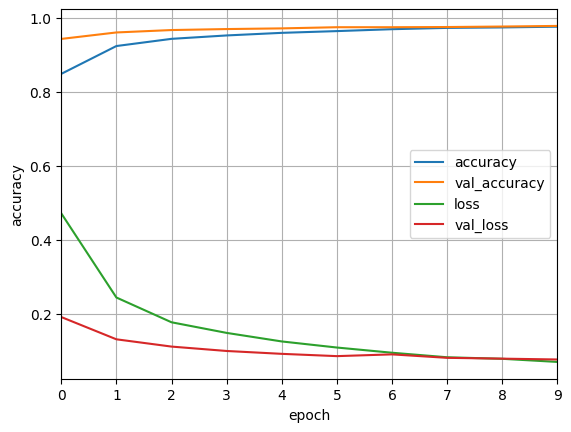

In [ ]:
# plot history
plt.plot(history_cnn['accuracy'])
plt.plot(history_cnn['val_accuracy'])
plt.plot(history_cnn['loss'])
plt.plot(history_cnn['val_loss'])
plt.xlim(0,9)
plt.grid()
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['accuracy', 'val_accuracy','loss', 'val_loss'], loc='best')
plt.show()


In [ ]:
# Evaluate model on test data

test_ds_cnn = TensorDataset(X_test, y_test)
test_loader_cnn = DataLoader(test_ds_cnn, batch_size=32, shuffle=False)

model.eval()
test_loss_sum = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for xb, yb in test_loader_cnn:
        xb = xb.to(device)
        yb = yb.to(device)

        logits = model(xb)
        loss = criterion(logits, yb)

        test_loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        test_correct += (preds == yb).sum().item()
        test_total += xb.size(0)

test_loss = test_loss_sum / test_total
test_acc = test_correct / test_total

print("Test Loss:", round(test_loss, 5), "\nTest Accuracy:", round(test_acc, 3))


Test Loss: 0.07055 
Test Accuracy: 0.979
